In [1]:
from google.colab import drive
import os,sys
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
sys.path.append('/content/drive/MyDrive/Github_proj/Deep-Learning-Study/ViT')

In [3]:
import math
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter,defaultdict
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
from torch.utils.data import Dataset,Subset,DataLoader,random_split
from tqdm.notebook import tqdm
from torch.optim.lr_scheduler import ReduceLROnPlateau
import itertools
import regex as re
import pickle

In [4]:
from dataset import *
from model import *
from methods import *
from train import *
from base_method import *

In [5]:
batch_size=128
n_val=5000
base_seed=67

In [6]:
train_loader,val_loader,test_loader,class_names=prepare_cifar10(data_root='/content/drive/MyDrive/data',batch_size=batch_size,n_val=n_val,base_seed=base_seed)
CIFAR10_MEAN=torch.tensor([0.4914, 0.4822, 0.4465])
CIFAR10_STD=torch.tensor([0.2470, 0.2435, 0.2616])

# Smoke Test

In [7]:
images,labels=None,None
smoke_cifar10=iter(train_loader)
smoke_images,smoke_labels=next(smoke_cifar10)
print(f"{smoke_images.shape}, {smoke_labels.shape}")

torch.Size([128, 3, 32, 32]), torch.Size([128])


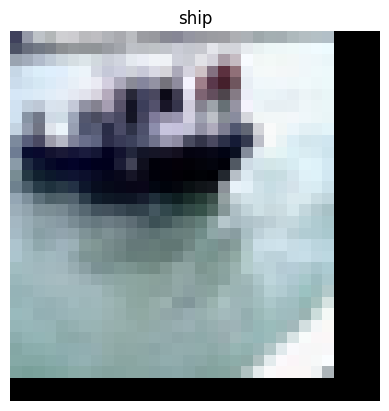

In [8]:
plt.imshow(smoke_images[6].permute(1,2,0)*CIFAR10_STD+CIFAR10_MEAN)
plt.title(class_names[smoke_labels[6]])
plt.axis('off')
plt.show()

# Setting

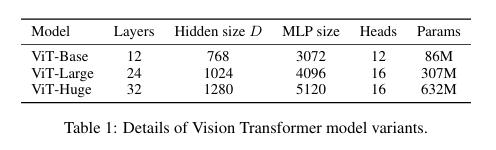

In [9]:
from dataclasses import dataclass

@dataclass
class ViTConfig_CIFAR10:
  img_size: int=32
  patch_size: int=4
  in_channels: int=3
  n_classes: int =10
  d_model: int =384
  n_layers: int =8
  heads: int =6
  bias: bool =True
  pos_p: float=0.1
  attn_p: float=0.1
  proj_p: float=0.1

In [10]:
epochs=30
warmup_epoch=5
device='cuda' if torch.cuda.is_available() else 'cpu'
base_seed=67

In [11]:
def build_optim(model, lr=1e-3, weight_decay=0.05, epochs=100, warmup_epoch=5):
    optimizer = optim.AdamW(model.parameters(), lr=lr,
                            betas=(0.9, 0.999), weight_decay=weight_decay)
    warmup = optim.lr_scheduler.LinearLR(
        optimizer, start_factor=1e-2, end_factor=1.0, total_iters=warmup_epoch)
    cosine = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs - warmup_epoch, eta_min=1e-6)
    scheduler = optim.lr_scheduler.SequentialLR(
        optimizer, schedulers=[warmup, cosine], milestones=[warmup_epoch])
    return optimizer, scheduler

In [14]:
cfg = ViTConfig_CIFAR10()
model_fns = {'ViT_cifar10_v1': VisionTransformer}

models, optimizers, schedulers = {}, {}, {}
for name, fn in model_fns.items():
    models[name] = fn(cfg).to(device)
    optimizers[name], schedulers[name] = build_optim(
        models[name], epochs=epochs, warmup_epoch=warmup_epoch)

criterion = nn.CrossEntropyLoss()

In [36]:
print(models)
print(optimizers)
print(schedulers)

{'ViT_cifar10_v1': VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(4, 4), stride=(4, 4))
  )
  (pos_embed): Embedding(65, 384)
  (pos_drop): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-7): 8 x TransformerBlock(
      (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiHeadAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (out_fc): Linear(in_features=384, out_features=384, bias=True)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=384, out_features=1536, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=1536, out_features=384, bias=True)
  

In [37]:
print(next(models['ViT_cifar10_v1'].parameters()).device)

cuda:0


# Training

In [15]:
save_path='/content/drive/MyDrive/Github_proj/Deep-Learning-Study/ViT/ckpts'

In [16]:
resume_epoch,resume_model_idx,batch_offset,running_loss,base_seed,best_losses,no_improves,es,train_loss_lists,val_loss_lists= load_ckpt(
    save_path,models,optimizers,schedulers, base_seed, device=device
)

In [73]:
#es=set()

Eval_interval=100,early_stop_epoch=5, max_norm=1.0

In [17]:
train_model(
    models, optimizers, schedulers, criterion,
    train_loader, val_loader,
    epochs, 100,
    best_losses, no_improves, es, 8, 1.0,
    resume_epoch, resume_model_idx, batch_offset, running_loss,
    train_loss_lists, val_loss_lists,
    ckpt_path=save_path, best_path=save_path,
    base_seed=base_seed, device=device
)

Epoch: 100%|##########| 30/30 [00:00<?, ?it/s]

In [67]:
print(train_loss_lists)
print(val_loss_lists)

print(best_losses)
print(no_improves)
print(es)

{'ViT_cifar10_v1': [1.8567737022584134, 1.702077284793962, 1.500922968103127, 1.4628900841555812, 1.5097080309959976, 1.583020482212305, 1.5697334263135085, 1.5327078297056935]}
{'ViT_cifar10_v1': [1.8441083401441574, 1.5119422912597655, 1.3360251367092133, 1.391468843817711, 1.4703223258256912, 1.588059628009796, 1.49730843603611, 1.409268581867218]}
{'ViT_cifar10_v1': 1.3360251367092133}
{'ViT_cifar10_v1': 5}
['ViT_cifar10_v1']


<Axes: title={'center': 'Loss_list'}, xlabel='Epoch', ylabel='Loss'>

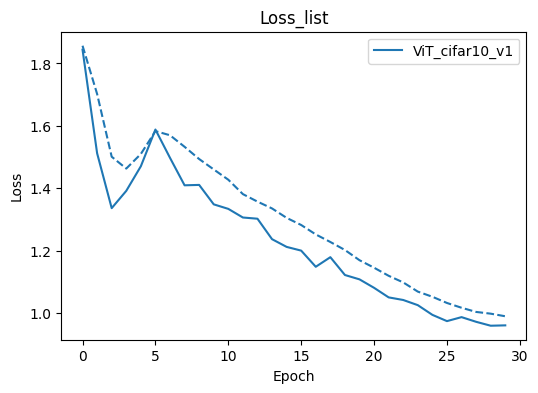

In [18]:
plot_loss_lists(train_loss_lists, val_loss_lists, names=None, ax=None, title="Loss_list")

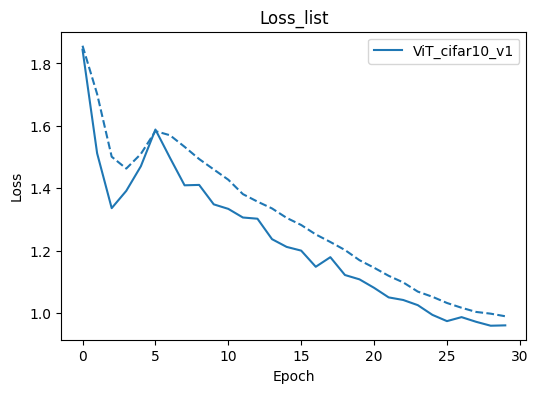

In [19]:
load_best(save_path,'ViT_cifar10_v1',models['ViT_cifar10_v1'],device)

In [22]:
acc=get_accuracy(test_loader,models['ViT_cifar10_v1'],device)
print(f'{acc:.2%}')

64.51%


In [41]:
tst_iter=iter(test_loader)

In [43]:
was_training = models['ViT_cifar10_v1'].training
models['ViT_cifar10_v1'].eval()

tst_images,tst_targets=next(tst_iter)
tst_images, tst_targets = tst_images.to(device), tst_targets.to(device)
tst_logits, tst_scores = models['ViT_cifar10_v1'](tst_images,True)

models['ViT_cifar10_v1'].train(was_training)

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(4, 4), stride=(4, 4))
  )
  (pos_embed): Embedding(65, 384)
  (pos_drop): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-7): 8 x TransformerBlock(
      (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiHeadAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (out_fc): Linear(in_features=384, out_features=384, bias=True)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=384, out_features=1536, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=1536, out_features=384, bias=True)
          (4): Dropou

In [44]:
tst_dist=compute_mean_attention_dist(tst_scores,ViTConfig_CIFAR10.patch_size)

<Axes: title={'center': 'CIFAR10'}, xlabel='Network depth (layer)', ylabel='Mean attention distance (pixels)'>

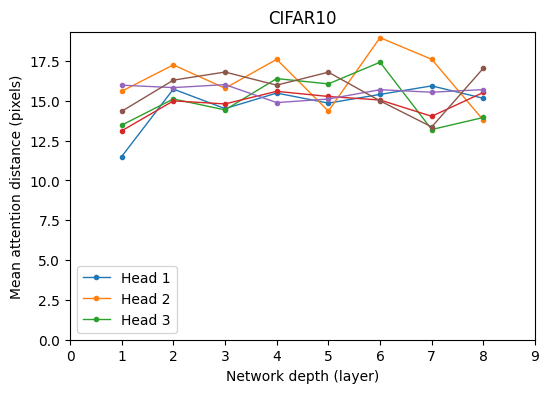

In [45]:
plot_attention_distance(tst_dist,title="CIFAR10",ax=None,legend_heads=3)

/content/drive/MyDrive/Github_proj/Deep-Learning-Study/ViT/methods.py:125: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  m = torch.tensor(mean).view(1, -1, 1, 1)
/content/drive/MyDrive/Github_proj/Deep-Learning-Study/ViT/methods.py:126: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  s = torch.tensor(std).view(1, -1, 1, 1)


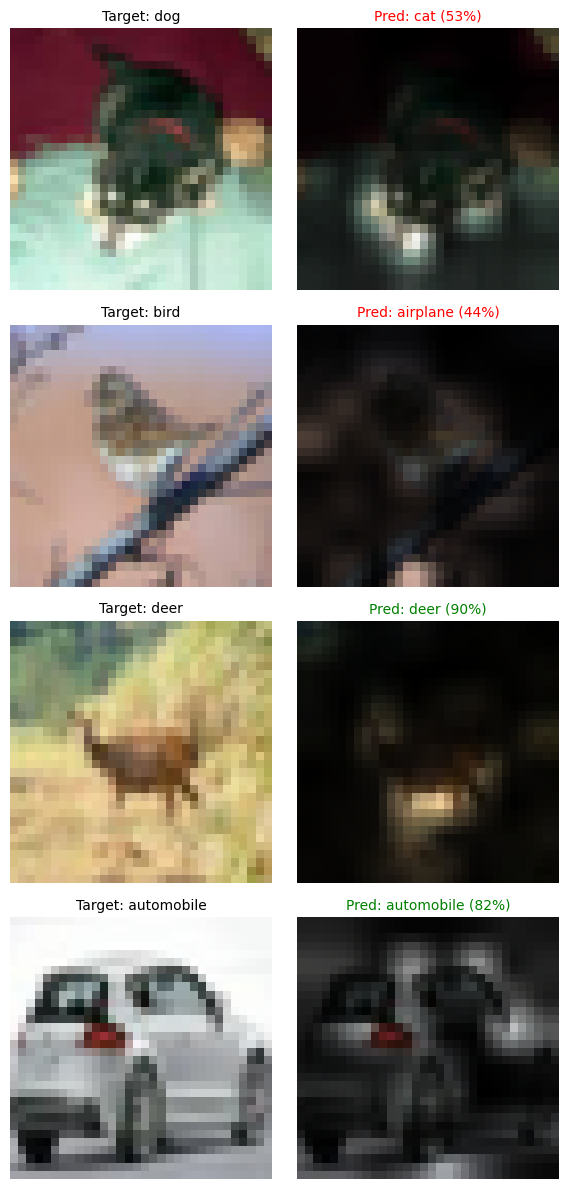

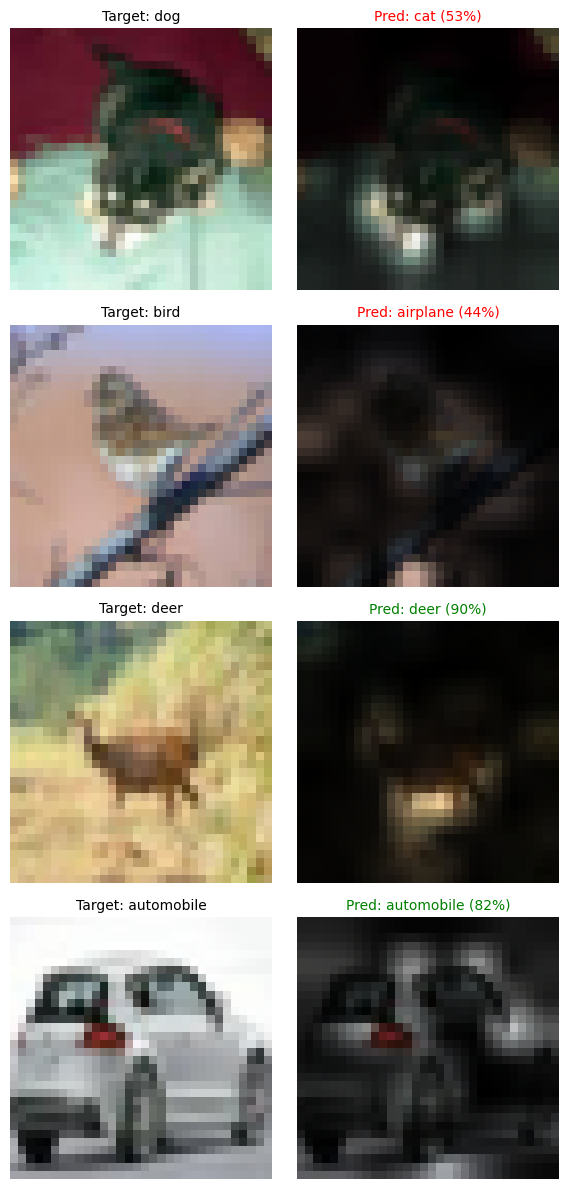

In [46]:
plot_attention_map(tst_images, tst_targets, tst_scores, tst_logits,class_names=class_names, mean=CIFAR10_MEAN, std=CIFAR10_STD,max_images=4, mode="mask")